
# Desafio 1 — Análise de Crédito | CredAIR

## 1. Entendimento do problema

O objetivo deste projeto é investigar os fatores associados à inadimplência em propostas de crédito e desenvolver um modelo de classificação utilizando Regressão Logística.

A variável resposta é *`inadimplente`*, que indica se uma proposta resultou ou não em inadimplência.

O problema será tratado como aprendizado supervisionado de classificação binária, pois os dados históricos possuem a resposta conhecida para cada registro.




In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#%pip install seaborn
import seaborn as sns


### 2. Análise exploratória

In [5]:
df = pd.read_csv("dataset.csv")
df

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,31,PB,Ensino Médio,3374.04,8,677,10198.45,24,Outros,2,0
4996,64,AM,Ensino Superior,3638.91,20,643,15374.40,24,Reforma,1,0
4997,48,MT,Ensino Médio,2211.31,21,486,8236.10,48,Saúde,0,1
4998,19,AP,Ensino Superior,14709.61,4,766,10617.90,18,Veículo,1,0


### •Métricas dos dados

In [6]:
display(df.describe().T)#Transpose

,count,mean,std,min,25%,50%,75%,max
idade,5000.0,47.767400,31.646099,18.00,32.00,46.00,61.0000,750.00
renda_mensal,5000.0,5228.633582,3968.478198,100.00,2697.32,4146.30,6458.8775,44814.19
tempo_emprego_anos,5000.0,12.662200,7.517539,1.00,6.00,13.00,19.0000,74.00
score_credito,5000.0,652.481200,84.817076,335.00,594.00,653.00,710.0000,850.00
valor_solicitado,5000.0,14264.657378,8268.261465,1721.48,8467.17,12365.63,17764.8850,50000.00
prazo_meses,5000.0,29.922000,15.482515,6.00,18.00,24.00,36.0000,60.00
dividas_ativas,5000.0,1.900400,1.864719,0.00,0.00,1.00,3.0000,7.00
inadimplente,5000.0,0.344000,0.475089,0.00,0.00,0.00,1.0000,1.00


In [7]:
colunas = df.isnull().any()
print(colunas)

display(df.columns[colunas])

print("Valores ausentes por coluna:")
print(df.isna().sum())

print("\nQuantidade de linhas duplicadas:")
print(df.duplicated().sum())

idade                 False
estado                False
escolaridade          False
renda_mensal          False
tempo_emprego_anos    False
score_credito         False
valor_solicitado      False
prazo_meses           False
finalidade            False
dividas_ativas        False
inadimplente          False
dtype: bool


Index([], dtype='str')

Valores ausentes por coluna:
idade                 0
estado                0
escolaridade          0
renda_mensal          0
tempo_emprego_anos    0
score_credito         0
valor_solicitado      0
prazo_meses           0
finalidade            0
dividas_ativas        0
inadimplente          0
dtype: int64

Quantidade de linhas duplicadas:
19


### •Como nas métricas foram identificados Idades e Tempo de Emprego acima do comum, será feito novas análises 

In [8]:
print("Idades acima de 100:")
display(df[df["idade"] > 100])

print("Tempo de emprego acima de 40 anos:")
display(df[df["tempo_emprego_anos"] > 40])

print("Quantidade de estados distintos:")
print(df["estado"].nunique())

print("Estados distintos:")
print(sorted(df["estado"].unique()))

Idades acima de 100:


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
482,660,CE,Ensino Superior,8737.57,7,626,11238.42,24,Saúde,1,0
697,680,RN,Ensino Médio,12067.28,20,535,8190.12,12,Educação,1,0
925,710,RS,Ensino Superior,2785.13,15,658,31054.95,18,Educação,0,0
975,430,TO,Ensino Superior,1883.08,10,598,21313.88,12,Veículo,4,1
987,300,SC,Ensino Médio,4748.00,19,655,10309.08,36,Viagem,0,0
1220,360,AC,Ensino Médio,4863.25,4,764,7974.62,18,Viagem,0,0
1263,440,DF,Ensino Superior,4330.45,18,542,34623.38,48,Educação,2,1
1290,280,RS,Ensino Médio,4146.73,5,534,23719.54,6,Reforma,0,1
1507,500,MT,Ensino Superior,2493.59,2,758,15382.55,18,Educação,0,0
2671,340,SC,Ensino Médio,12069.75,8,683,11191.93,48,Reforma,4,0


Tempo de emprego acima de 40 anos:


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
388,56,RR,Ensino Médio,16193.38,57,617,7028.37,48,Reforma,0,0
850,62,PA,Ensino Fundamental,3741.96,63,730,12445.89,6,Veículo,1,1
1937,73,DF,Ensino Fundamental,2609.94,74,721,13972.16,36,Reforma,0,0
2659,45,RJ,Ensino Superior,2797.80,46,690,7981.42,48,Outros,1,0
2711,56,BA,Ensino Médio,2109.55,57,598,19541.27,36,Reforma,1,1
3162,64,MS,Ensino Médio,1996.15,65,597,15080.16,24,Veículo,1,0
4655,66,SP,Ensino Médio,2391.84,67,718,19779.15,24,Outros,2,1


Quantidade de estados distintos:
85
Estados distintos:
['  AC ', '  AL ', '  AL  ', '  AM ', '  CE ', '  DF ', '  GO ', '  MG ', '  MS ', '  PA ', '  PB ', '  PB  ', '  PE  ', '  PI ', '  RO  ', '  RR ', '  RR  ', '  RS ', '  RS  ', '  SE ', '  SE  ', '  SP ', '  SP  ', ' AC  ', ' AL ', ' AM ', ' AM  ', ' AP  ', ' BA ', ' CE ', ' DF ', ' ES ', ' GO ', ' GO  ', ' MA ', ' MG ', ' MG  ', ' MS ', ' MT  ', ' PA ', ' PB ', ' PB  ', ' PE ', ' PE  ', ' PI ', ' PI  ', ' RJ ', ' RJ  ', ' RN ', ' RN  ', ' RO ', ' RR ', ' RR  ', ' SC ', ' SC  ', ' SE ', ' SE  ', ' TO ', 'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


•Também foi identificado a coluna Estado com mais Estados do que deveria, será filtrado para analisar

In [40]:
print("Estados com espaços extras:")

display(
    df.loc[
        df["estado"] != df["estado"].str.strip(),
        ["estado"]
    ].drop_duplicates()
    .sort_values("estado")
)

Estados com espaços extras:


,estado


### •Verificar a variável resposta

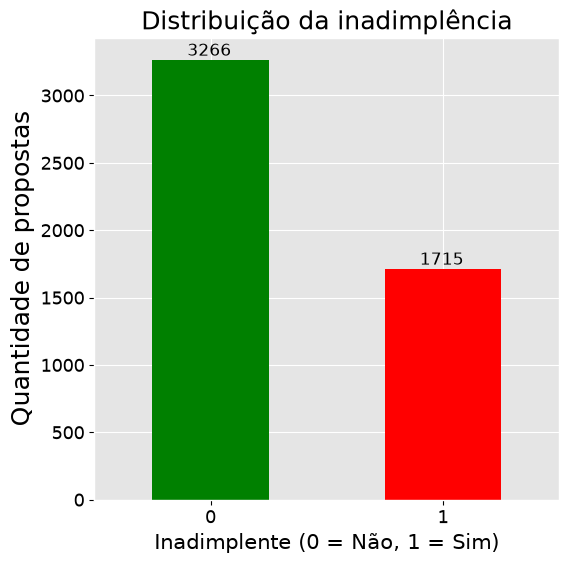

In [ ]:
inadimplente = df["inadimplente"].value_counts()

grf = inadimplente.plot(
    kind='bar',
    rot=0, 
    figsize=(6,6),
    color=["green", "red"],#cores das barras
    fontsize=13,
    label='inadimplente'
    )

for i in grf.patches:
    grf.text(
        i.get_x() + 0.15, #0.15 é para colocar o valor mais no centro da barra
        i.get_height()+30,#+30 é para colocar o valor mais acima da barra
        i.get_height(), 
        color='black',
        fontsize=12
    )
grf.tick_params(axis="both", colors="black")#deixar valores de X e Y pretos

plt.style.use('ggplot')
plt.title("Distribuição da inadimplência", fontsize=18, color='black')
plt.xlabel("Inadimplente (0 = Não, 1 = Sim)", fontsize=15, color='black')
plt.ylabel("Quantidade de propostas", fontsize=18, color='black')
plt.show()

### •Dividir os Scores em faixas para análise.

In [102]:
faixas_score = pd.cut(
    df["score_credito"],
    bins=[0, 500, 600, 700, 800, 1000],
    right=False
)

taxa_score = (
    df.groupby(faixas_score, observed=False)["inadimplente"]
      .agg(["count", "mean"])
)

taxa_score["mean"] = taxa_score["mean"] * 100

display(taxa_score.rename(columns={
    "count": "quantidade",
    "mean": "taxa_inadimplencia_%"
}))

,quantidade,taxa_inadimplencia_%
score_credito,,
"[0, 500)",187,63.636364
"[500, 600)",1158,51.727116
"[600, 700)",2168,34.178967
"[700, 800)",1249,18.574860
"[800, 1000)",219,10.958904


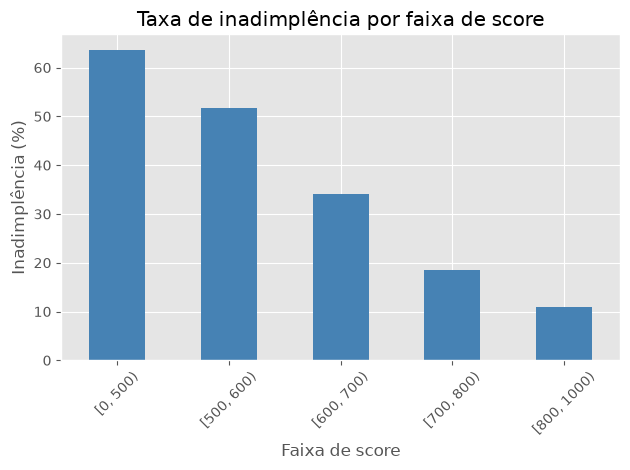

In [ ]:
taxa_score["mean"].plot(kind="bar", color="steelblue")

plt.title("Taxa de inadimplência por faixa de score")
plt.xlabel("Faixa de score")
plt.ylabel("Inadimplência (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### •Em uma analise Rápida, da pra ver que quanto menor o Score, menor a taxa de inadimplência

In [13]:
# Taxa de inadimplência por quantidade de dívidas
display(
    df.groupby("dividas_ativas")["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
      .assign(taxa_inadimplencia=lambda x: x["taxa_inadimplencia"] * 100)
      .round(2)
)

taxa_dividas = (
    df.groupby("dividas_ativas")["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
)

taxa_dividas["taxa_inadimplencia"] *= 100

display(taxa_dividas.round(2))

# Estatísticas financeiras por classe
display(
    df.groupby("inadimplente")[
        ["renda_mensal", "valor_solicitado", "prazo_meses"]
    ].mean().round(2)
)

,quantidade,taxa_inadimplencia
dividas_ativas,,
0,1554,27.41
1,965,26.84
2,848,36.32
3,631,38.67
4,420,46.19
5,322,45.65
6,162,51.23
7,98,60.20


,quantidade,taxa_inadimplencia
dividas_ativas,,
0,1554,27.41
1,965,26.84
2,848,36.32
3,631,38.67
4,420,46.19
5,322,45.65
6,162,51.23
7,98,60.20


,renda_mensal,valor_solicitado,prazo_meses
inadimplente,,,
0,5770.95,13404.56,31.05
1,4194.45,15904.85,27.77


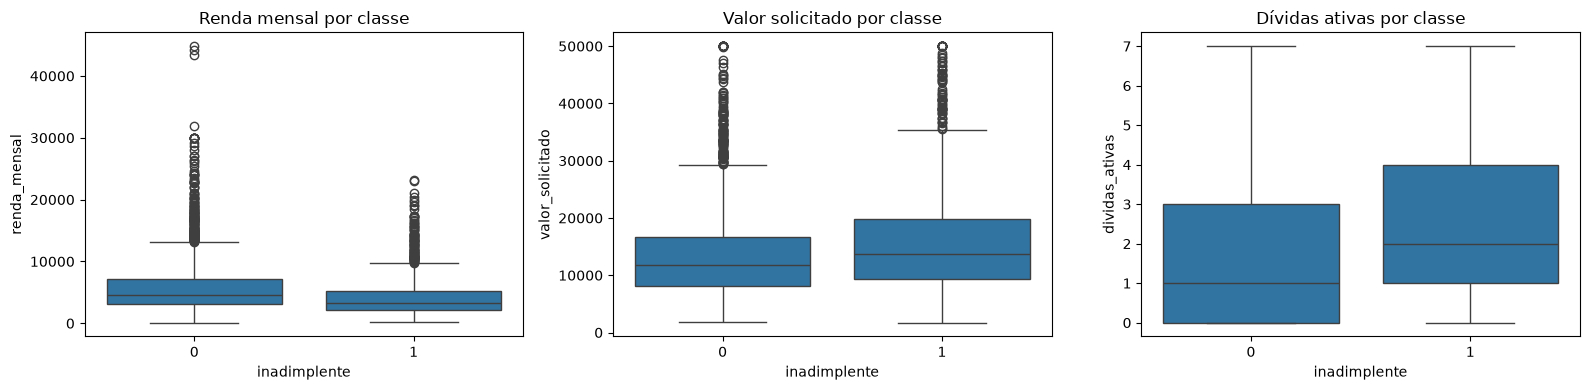

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="inadimplente", y="renda_mensal", ax=axes[0])
axes[0].set_title("Renda mensal por classe")

sns.boxplot(data=df, x="inadimplente", y="valor_solicitado", ax=axes[1])
axes[1].set_title("Valor solicitado por classe")

sns.boxplot(data=df, x="inadimplente", y="dividas_ativas", ax=axes[2])
axes[2].set_title("Dívidas ativas por classe")

# sns.boxplot(data=df, x="inadimplente", y="idade", ax=axes[3])
# axes[3].set_title("Dívidas ativas por Idade")

plt.tight_layout()
plt.show()

### Análise das distribuições por classe

Os boxplots indicam diferenças nas distribuições de renda mensal, valor solicitado e quantidade de dívidas ativas entre as classes de inadimplência. Os solicitantes inadimplentes aparentam apresentar menor renda mediana, maior valor mediano de empréstimo solicitado e maior quantidade mediana de dívidas ativas. Também foram observadas diversas observações potencialmente atípicas nas variáveis financeiras. Esses resultados são exploratórios e sugerem associações que deverão ser investigadas nas próximas etapas, sem permitir conclusões causais.

In [15]:
df["faixa_renda"] = pd.cut(
    df["renda_mensal"],
    bins=[0, 2000, 4000, 6000, 10000, float("inf")],
    labels=[
        "Até 2 mil",
        "2 a 4 mil",
        "4 a 6 mil",
        "6 a 10 mil",
        "Acima de 10 mil"
    ]
)

taxa_renda = (
    df.groupby("faixa_renda", observed=False)["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
)

taxa_renda["taxa_inadimplencia"] *= 100

display(taxa_renda.round(2))

,quantidade,taxa_inadimplencia
faixa_renda,,
Até 2 mil,639,54.62
2 a 4 mil,1766,40.15
4 a 6 mil,1188,28.96
6 a 10 mil,924,24.46
Acima de 10 mil,483,19.05


### Análise da inadimplência por dívidas ativas e renda

A análise da taxa de inadimplência por quantidade de dívidas ativas revelou uma tendência geral de aumento da inadimplência em grupos com maior número de dívidas. A taxa variou de 26,84% entre solicitantes com uma dívida para 60,20% entre aqueles com sete dívidas ativas.

Em relação à renda mensal, observou-se uma associação inversa entre a faixa de renda e a taxa de inadimplência. O grupo com renda de até R$ 2.000 apresentou taxa de 54,62%, enquanto o grupo com renda superior a R$ 10.000 apresentou taxa de 19,05%.

Esses resultados sugerem que a quantidade de dívidas ativas e a renda mensal são variáveis relevantes para investigar o risco de inadimplência. Entretanto, as associações observadas não demonstram causalidade e deverão ser avaliadas em conjunto com as demais variáveis e com os resultados do modelo preditivo.


## 3. Limpeza e preparação dos dados

Nesta etapa, serão investigadas e tratadas inconsistências nos dados, incluindo espaços extras nas variáveis categóricas, registros duplicados e valores inválidos.

As decisões de tratamento serão documentadas antes da modelagem.


In [16]:
# Recarregar o arquivo original para evitar alterações
# feitas durante a análise exploratória
df = pd.read_csv("dataset.csv")

# Padronizar espaços nas colunas de texto
colunas_texto = df.select_dtypes(include="object").columns

for coluna in colunas_texto:
    df[coluna] = df[coluna].str.strip()

# Verificar duplicidades exatas
print("Duplicidades:", df.duplicated().sum())

# Remover registros duplicados
df = df.drop_duplicates().copy()

print("Dimensões após remoção:", df.shape)

Duplicidades: 19
Dimensões após remoção: (4981, 11)


C:\Users\Diniz\AppData\Local\Temp\ipykernel_150048\3735001894.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_texto = df.select_dtypes(include="object").columns


In [17]:
# Idades fora de uma faixa plausível
df.loc[
    (df["idade"] < 18) | (df["idade"] > 100),
    "idade"
] = np.nan

# Tempo de emprego inválido
df.loc[
    (df["tempo_emprego_anos"] < 0) |
    (df["tempo_emprego_anos"] > df["idade"]),
    "tempo_emprego_anos"
] = np.nan

# Verificar o resultado
display(df[["idade", "tempo_emprego_anos"]].describe())
print(df[["idade", "tempo_emprego_anos"]].isna().sum())

,idade,tempo_emprego_anos
count,4966.000000,4973.000000
mean,46.408377,12.588377
std,16.786857,7.287819
min,18.000000,1.000000
25%,32.000000,6.000000
50%,46.000000,13.000000
75%,61.000000,19.000000
max,75.000000,25.000000


idade                 15
tempo_emprego_anos     8
dtype: int64


In [18]:
# Evitar divisão por zero ou renda inválida
df.loc[df["renda_mensal"] <= 0, "renda_mensal"] = np.nan

df["proporcao_emprestimo_renda_anual"] = (
    df["valor_solicitado"] /
    (df["renda_mensal"] * 12)
)

In [19]:
df.head()

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente,proporcao_emprestimo_renda_anual
0,52.0,MS,Ensino Superior,2911.82,14.0,690,5934.19,60,Viagem,1,0,0.169830
1,49.0,RR,Ensino Médio,3176.43,5.0,676,6791.38,24,Outros,2,0,0.178171
2,48.0,AL,Ensino Superior,3429.40,23.0,558,14666.78,24,Outros,5,1,0.356398
3,59.0,GO,Ensino Fundamental,10096.70,2.0,739,19053.24,24,Reforma,0,0,0.157256
4,37.0,RJ,Ensino Fundamental,3033.25,24.0,797,6171.31,6,Educação,0,1,0.169546


In [ ]:
#%pip install scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [20]:
# Separar a variável resposta das variáveis explicativas
X = df.drop(columns=["inadimplente"])
y = df["inadimplente"]

# Identificar os tipos de variáveis
colunas_numericas = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

colunas_categoricas = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Variáveis numéricas:", colunas_numericas)
print("Variáveis categóricas:", colunas_categoricas)

Variáveis numéricas: ['idade', 'renda_mensal', 'tempo_emprego_anos', 'score_credito', 'valor_solicitado', 'prazo_meses', 'dividas_ativas', 'proporcao_emprestimo_renda_anual']
Variáveis categóricas: ['estado', 'escolaridade', 'finalidade']


C:\Users\Diniz\AppData\Local\Temp\ipykernel_150048\3050958581.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_categoricas = X.select_dtypes(


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

Treino: (3984, 11)
Teste: (997, 11)


In [22]:
# Preparação das variáveis numéricas
preparo_numerico = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("escala", StandardScaler())
])

# Preparação das variáveis categóricas
preparo_categorico = Pipeline([
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

# Aplicar a preparação correta para cada tipo de variável
preparo = ColumnTransformer([
    ("num", preparo_numerico, colunas_numericas),
    ("cat", preparo_categorico, colunas_categoricas)
])

# Pipeline completo: preparação + modelo
modelo = Pipeline([
    ("preparo", preparo),
    ("classificador", LogisticRegression(max_iter=1000))
])

# Treinar
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [23]:
# Previsões de classe
y_pred = modelo.predict(X_test)

# Probabilidade estimada de inadimplência
y_prob = modelo.predict_proba(X_test)[:, 1]

print("Acurácia:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred))

Acurácia: 0.7332
ROC-AUC: 0.7657

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.76      0.88      0.81       654
           1       0.66      0.46      0.54       343

    accuracy                           0.73       997
   macro avg       0.71      0.67      0.68       997
weighted avg       0.72      0.73      0.72       997


Matriz de confusão:
[[574  80]
 [186 157]]


In [32]:
# Probabilidade prevista de inadimplência (classe 1)
probabilidades = modelo.predict_proba(X_test)[:, 1]

# Testar diferentes thresholds
for threshold in [0.3, 0.4, 0.5, 0.6]:
    previsoes = (probabilidades >= threshold).astype(int)



    print(f"\n{'=' * 60}")
    print(f"THRESHOLD: {threshold}")
    print("Acurácia:", round(accuracy_score(y_test, previsoes), 4))
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilidades), 4))    
    print(classification_report(y_test, previsoes, zero_division=0))
    print("Matriz de confusão:")
    print(confusion_matrix(y_test, previsoes))


THRESHOLD: 0.3
Acurácia: 0.6841
ROC-AUC: 0.7657
              precision    recall  f1-score   support

           0       0.82      0.66      0.73       654
           1       0.53      0.73      0.61       343

    accuracy                           0.68       997
   macro avg       0.68      0.69      0.67       997
weighted avg       0.72      0.68      0.69       997

Matriz de confusão:
[[432 222]
 [ 93 250]]

THRESHOLD: 0.4
Acurácia: 0.7292
ROC-AUC: 0.7657
              precision    recall  f1-score   support

           0       0.80      0.79      0.79       654
           1       0.61      0.61      0.61       343

    accuracy                           0.73       997
   macro avg       0.70      0.70      0.70       997
weighted avg       0.73      0.73      0.73       997

Matriz de confusão:
[[517 137]
 [133 210]]

THRESHOLD: 0.5
Acurácia: 0.7332
ROC-AUC: 0.7657
              precision    recall  f1-score   support

           0       0.76      0.88      0.81       654
    

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Pipeline: preparação dos dados + Random Forest
modelo_rf = Pipeline([
    ("preparo", preparo),
    ("classificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Treinar o modelo
modelo_rf.fit(X_train, y_train)

# Fazer previsões
previsoes_rf = modelo_rf.predict(X_test)
probabilidades_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Avaliar o resultado
print("Acurácia:", round(accuracy_score(y_test, previsoes_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilidades_rf), 4))

print("\nRelatório de classificação:")
print(classification_report(y_test, previsoes_rf, zero_division=0))

print("Matriz de confusão:")
print(confusion_matrix(y_test, previsoes_rf))

Acurácia: 0.7282
ROC-AUC: 0.7616

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.78      0.81      0.80       654
           1       0.61      0.57      0.59       343

    accuracy                           0.73       997
   macro avg       0.70      0.69      0.69       997
weighted avg       0.72      0.73      0.73       997

Matriz de confusão:
[[530 124]
 [147 196]]


In [38]:
modelo_rf_ajustado = Pipeline([
    ("preparo", preparo),
    ("classificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        max_depth=8,
        min_samples_leaf=10
    ))
])

modelo_rf_ajustado.fit(X_train, y_train)

previsoes_rf_ajustado = modelo_rf_ajustado.predict(X_test)
probabilidades_rf_ajustado = modelo_rf_ajustado.predict_proba(X_test)[:, 1]

print("Acurácia:",round(accuracy_score(y_test, previsoes_rf_ajustado), 4))

print("ROC-AUC:",round(roc_auc_score(y_test, probabilidades_rf_ajustado), 4))

print("\nRelatório de classificação:")
print(classification_report(
    y_test, previsoes_rf_ajustado, zero_division=0
))

print("Matriz de confusão:")
print(confusion_matrix(y_test, previsoes_rf_ajustado))

Acurácia: 0.7091
ROC-AUC: 0.7743

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.81      0.73      0.77       654
           1       0.57      0.66      0.61       343

    accuracy                           0.71       997
   macro avg       0.69      0.70      0.69       997
weighted avg       0.72      0.71      0.71       997

Matriz de confusão:
[[479 175]
 [115 228]]
